<a href="https://colab.research.google.com/github/josmimaria/Machine-Learning/blob/development/Diabetes_prediction_dataset_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [4]:
filepath = '/content/drive/MyDrive/Dataset/diabetes.csv'
dataset = pd.read_csv(filepath)
dataset.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
data = dataset.to_dict(orient ='records')

In [ ]:
# Insert records in the dataset into MongoDB collection

In [7]:
df = pd.DataFrame(dataset)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


# Data Cleaning

In [9]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [10]:
df[df.isnull().any(axis=1)]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome


There is no empty or null values in this dataset

In [12]:
df.shape

(768, 9)

In [13]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [25]:
df['Outcome'].unique()

array([1, 0])

In [16]:
df.Outcome.value_counts()

,count
Outcome,
0,500
1,268


### Visualization of Distribution

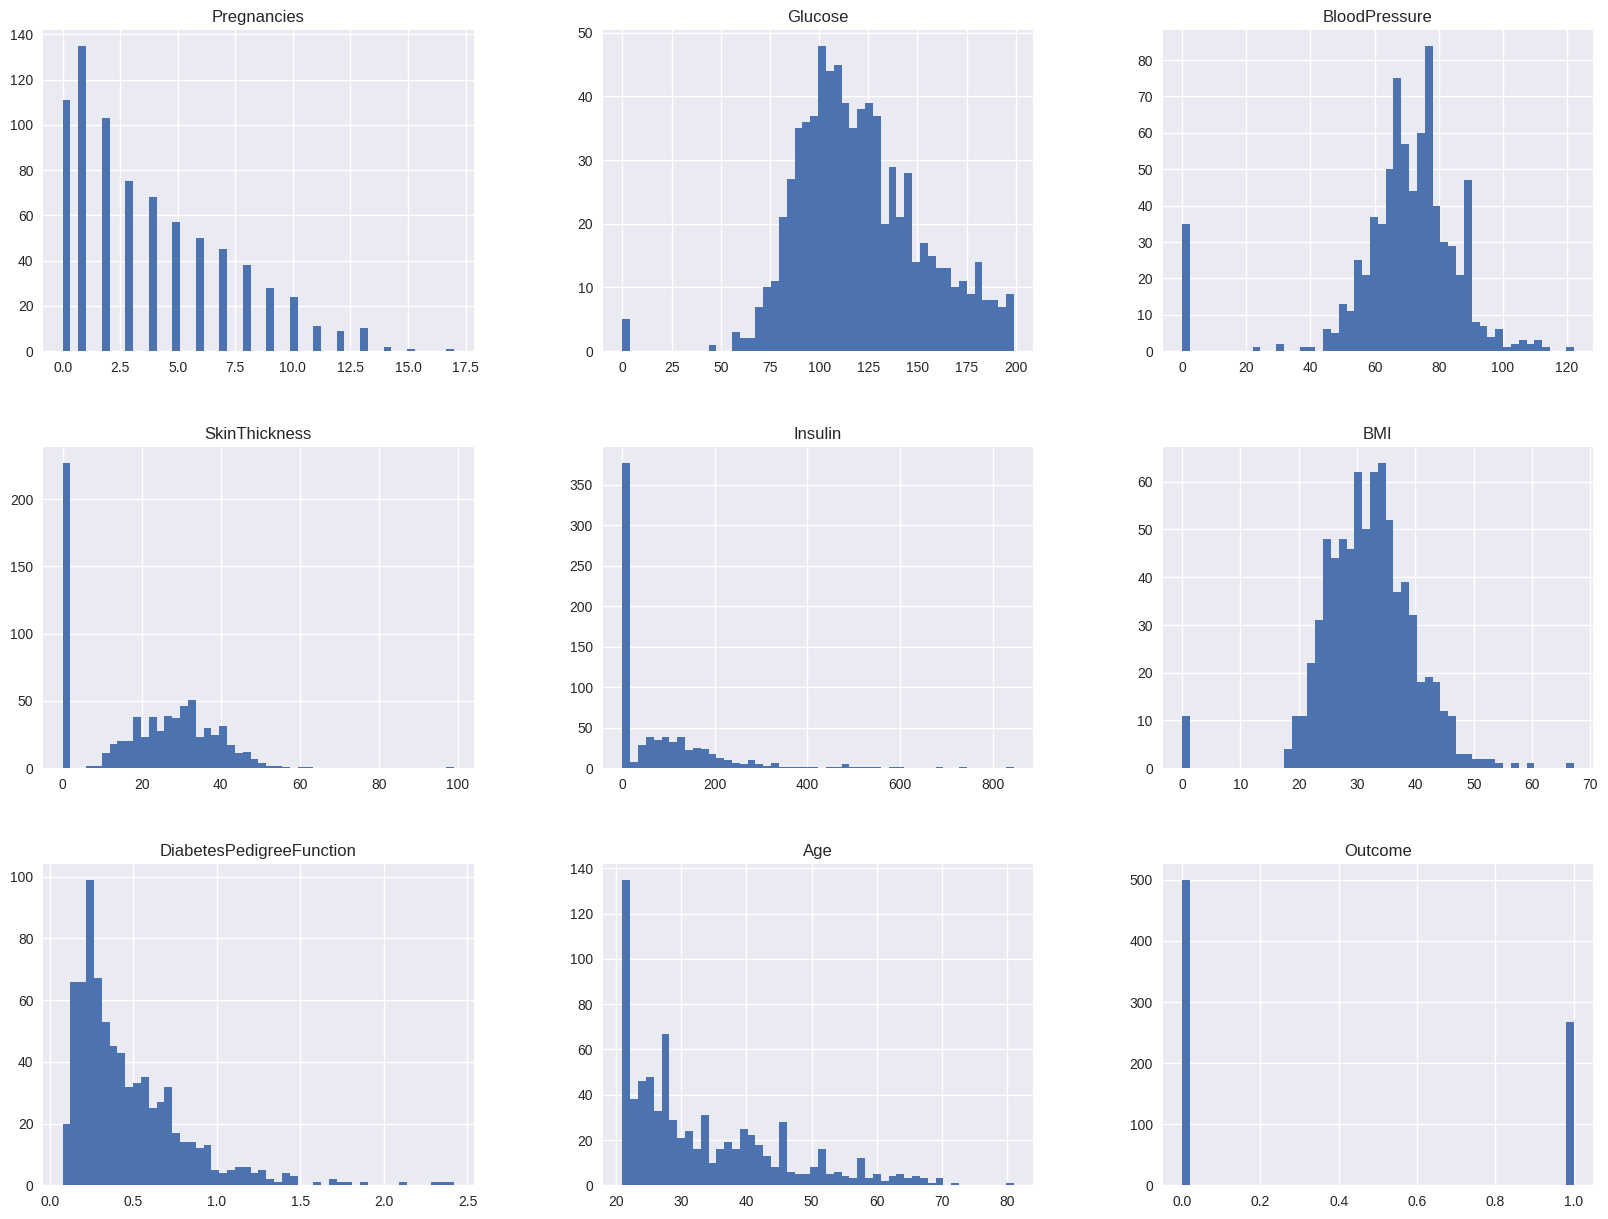

In [20]:
plt.style.use('seaborn-v0_8')
df.hist(bins=50,figsize=(20,15),ec='b')
plt.show()

In [21]:
percentage = df.Outcome.value_counts(normalize=True)
percentage

,proportion
Outcome,
0,0.651042
1,0.348958


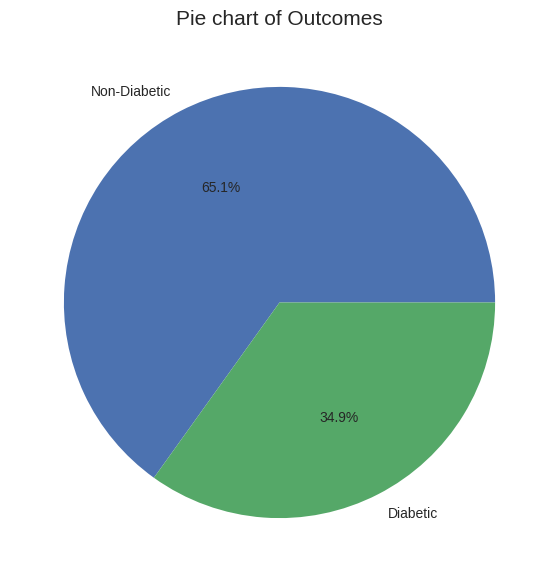

In [23]:
# Plotting Pie Chart
Classlabels = ['Non-Diabetic','Diabetic']
plt.figure(figsize=(12,7))
plt.pie(percentage, labels=Classlabels, autopct='%1.1f%%')
plt.title('Pie chart of Outcomes', fontsize=15)
plt.show()

# Checking Multicollinearity

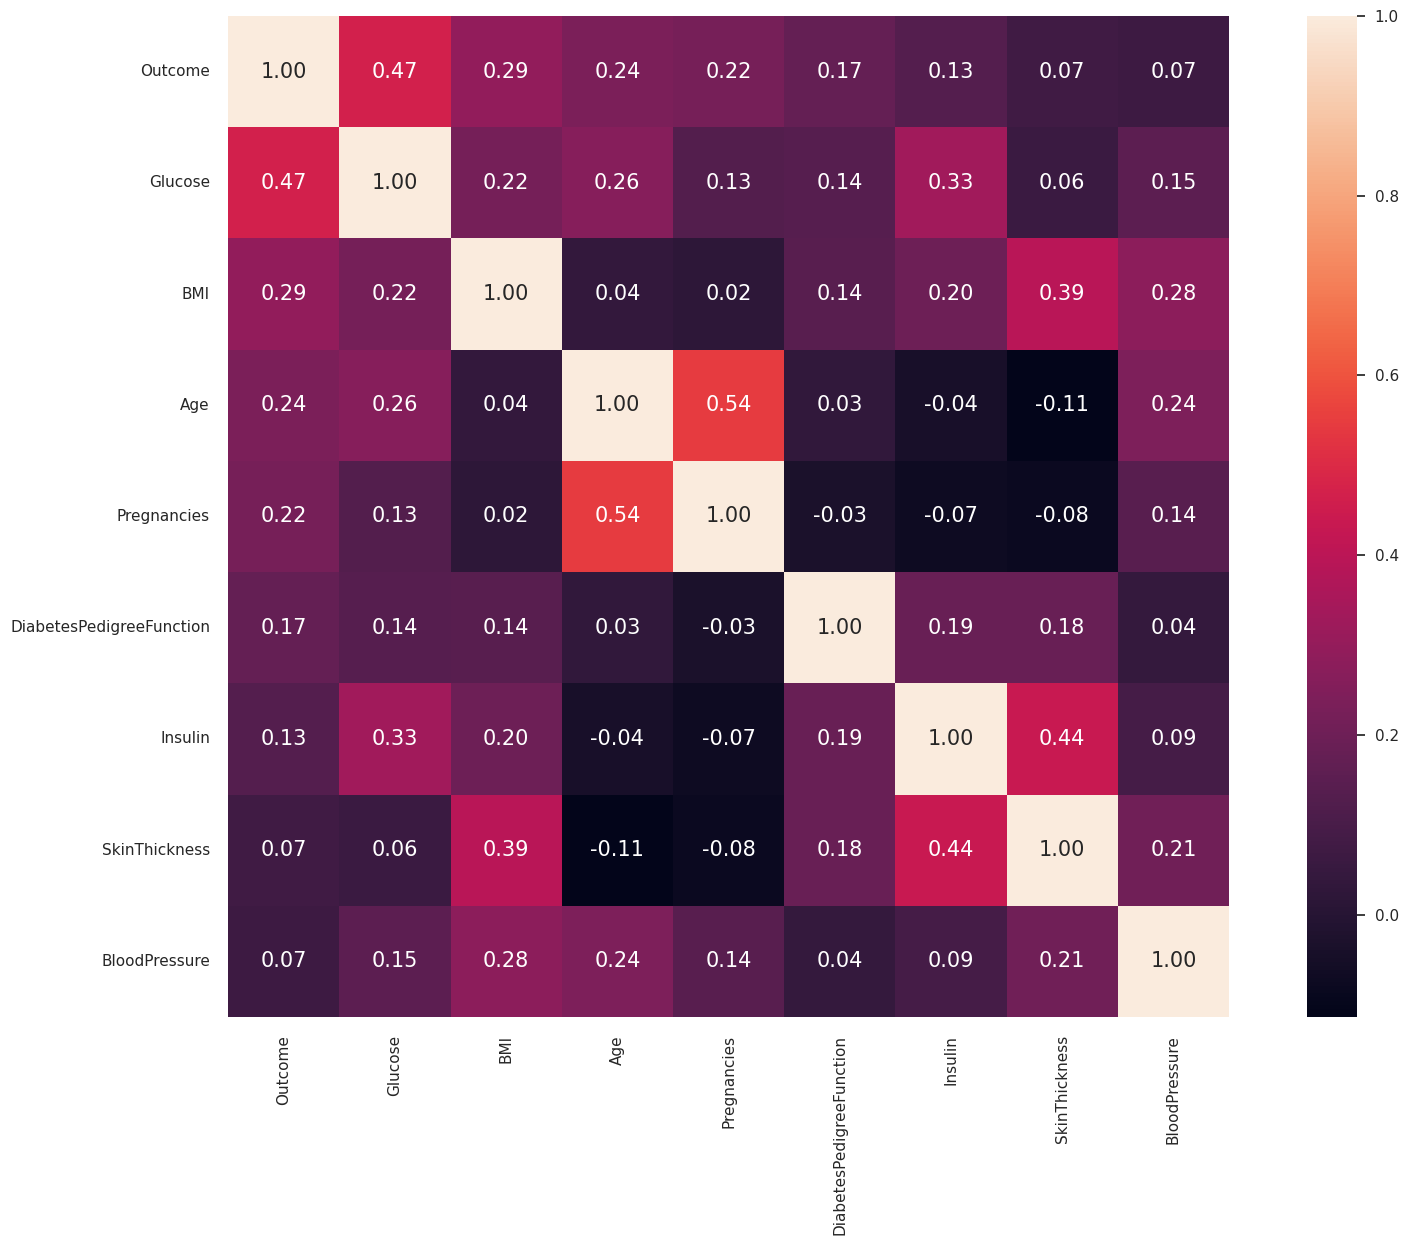

In [26]:
k = len(df.columns)
cols = df.corr().nlargest(k,'Outcome')['Outcome'].index
cm = np.corrcoef(df[cols].values.T)
sns.set(font_scale=1)
f,ax = plt.subplots(figsize=(20,13))
hm= sns.heatmap(cm, annot=True, square=True, fmt='.2f', annot_kws={'size':15}, xticklabels=cols.values, yticklabels=cols.values)
plt.show()

### People with more pregnancies may have a higher chance of having diabetes.

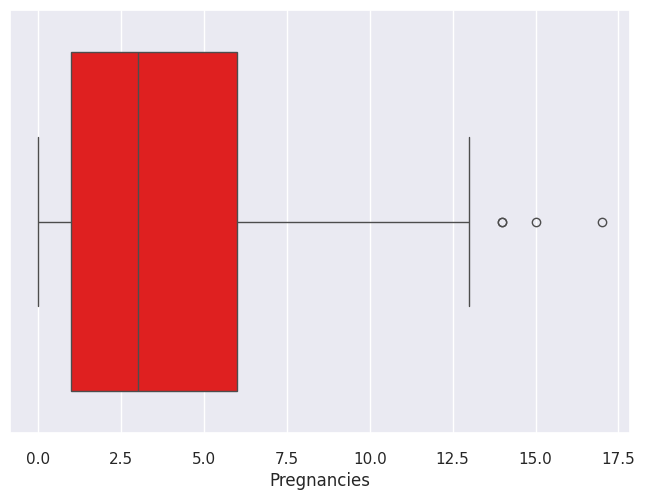

In [29]:
ax = sns.boxplot(x=df['Pregnancies'],color='red')

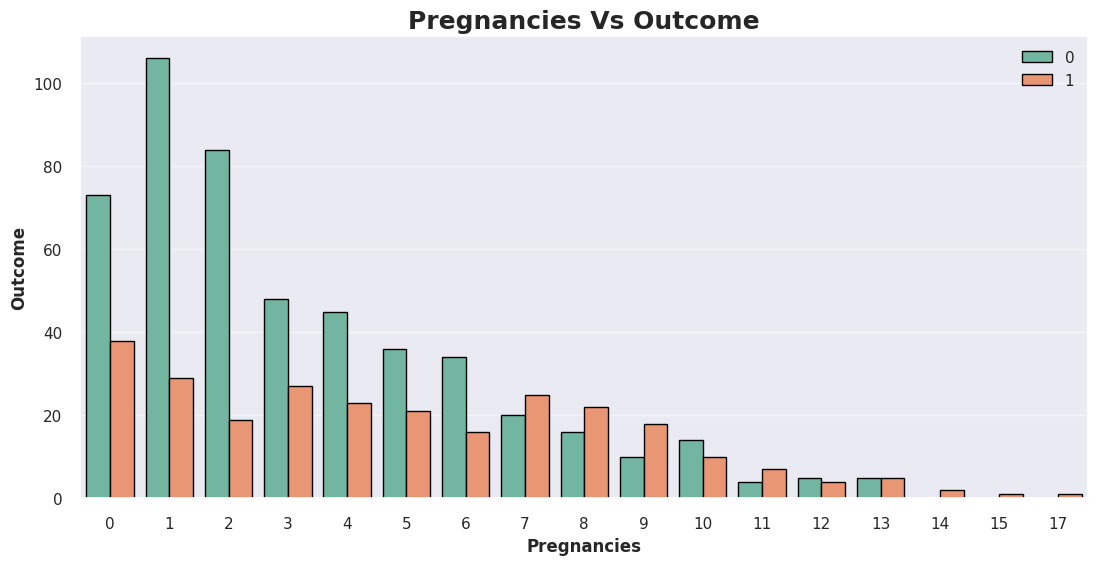

In [30]:

plt.subplots(figsize=(13,6))
sns.set_style('whitegrid')
sns.countplot(x='Pregnancies',hue='Outcome',data= df,ec = 'black', palette= 'Set2')
plt.title('Pregnancies Vs Outcome', fontsize=18, weight='bold')
plt.ylabel('Outcome', weight = 'bold')
plt.xlabel('Pregnancies', weight= 'bold')
plt.legend(loc='upper right')
plt.grid(alpha = 0.5,axis = 'y')
plt.show()

In [36]:
k = len(df.columns)
cols = df.corr().nlargest(k,'Outcome')['Outcome'].index
cols

Index(['Outcome', 'Glucose', 'BMI', 'Age', 'Pregnancies',
       'DiabetesPedigreeFunction', 'Insulin', 'SkinThickness',
       'BloodPressure'],
      dtype='object')

In [32]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [45]:
def histogram(feature, xlabel):
    plt.figure(figsize=[14, 8])
    ax = sns.histplot(data=df, x=feature, hue='Outcome',
                      bins=10, multiple='stack', edgecolor='black')
    ax.set(xlabel=xlabel, ylabel='Number of Diabetes and Non-Diabetes Cases')
    plt.tight_layout()
    plt.show()

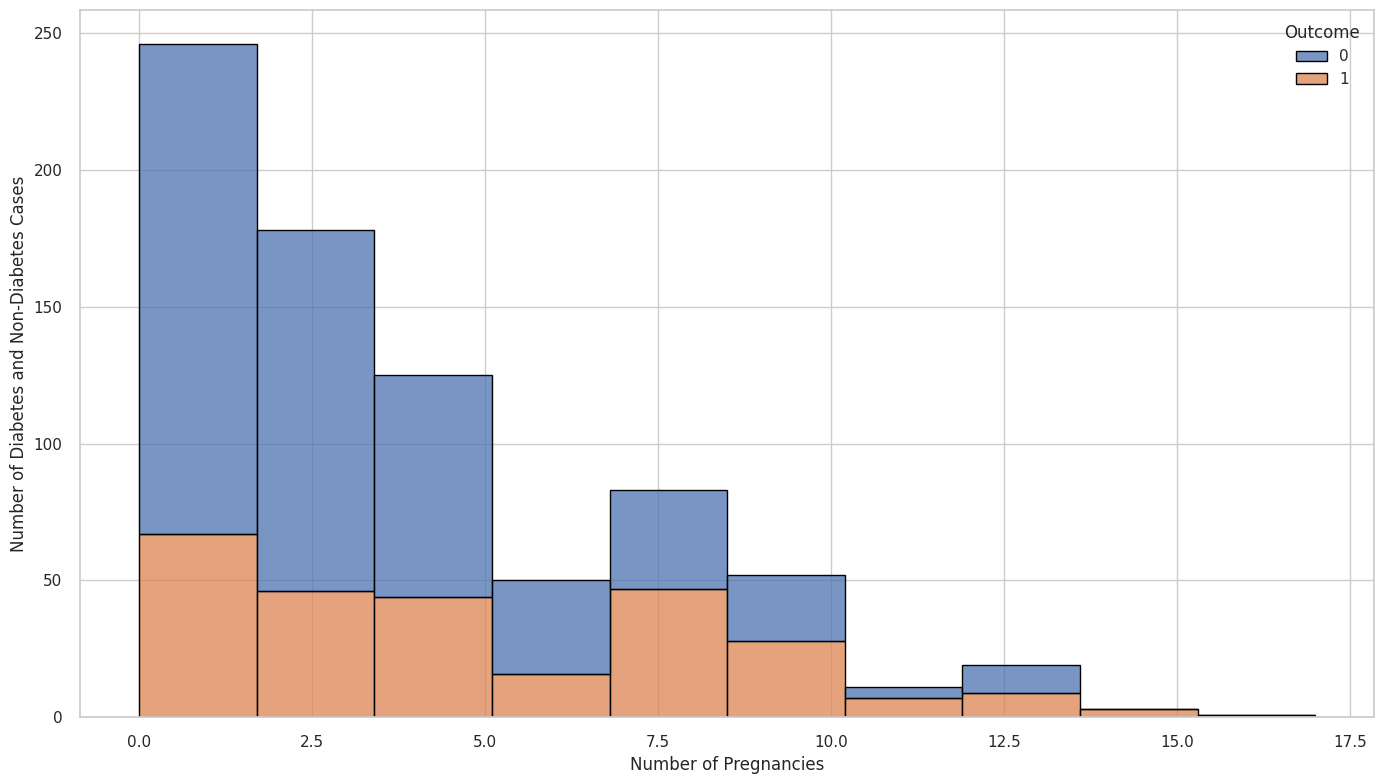

In [46]:
histogram('Pregnancies','Number of Pregnancies')

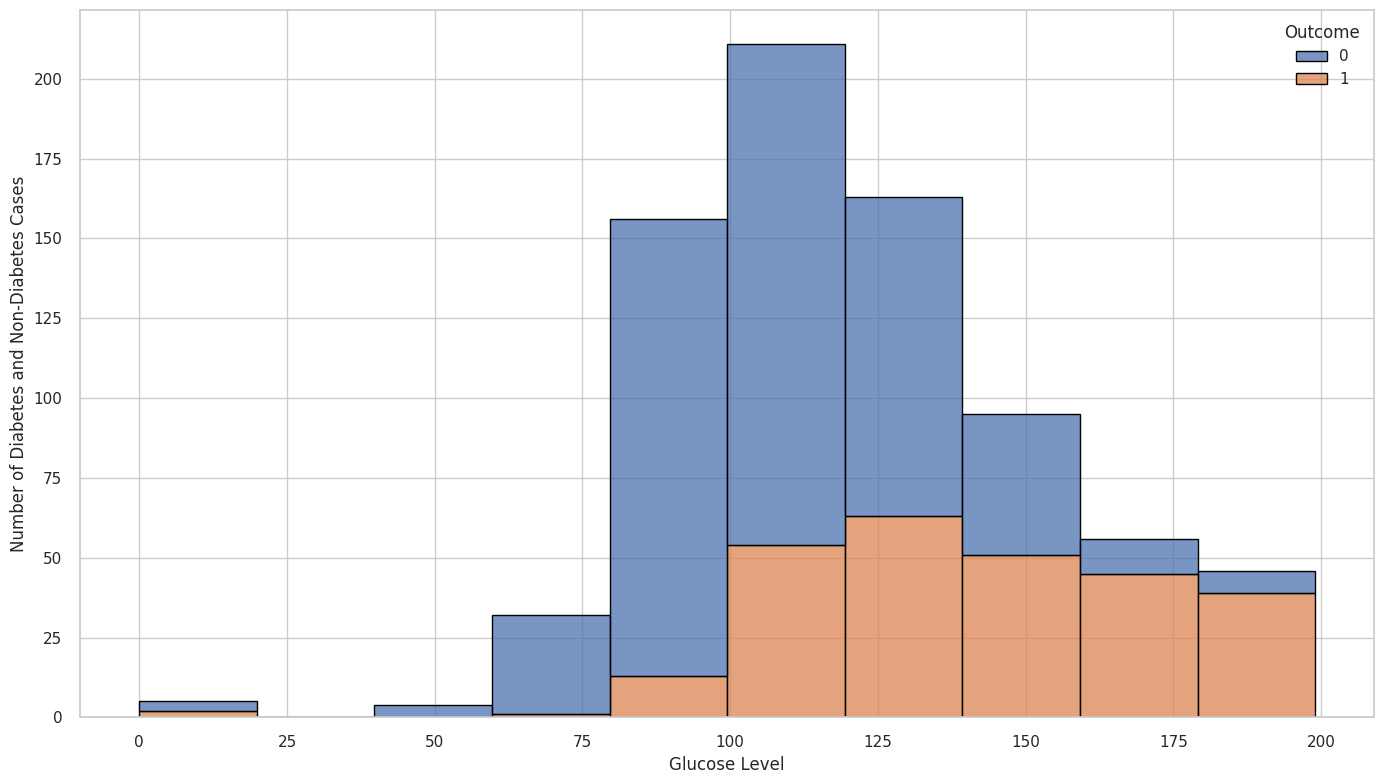

In [47]:
histogram('Glucose','Glucose Level')

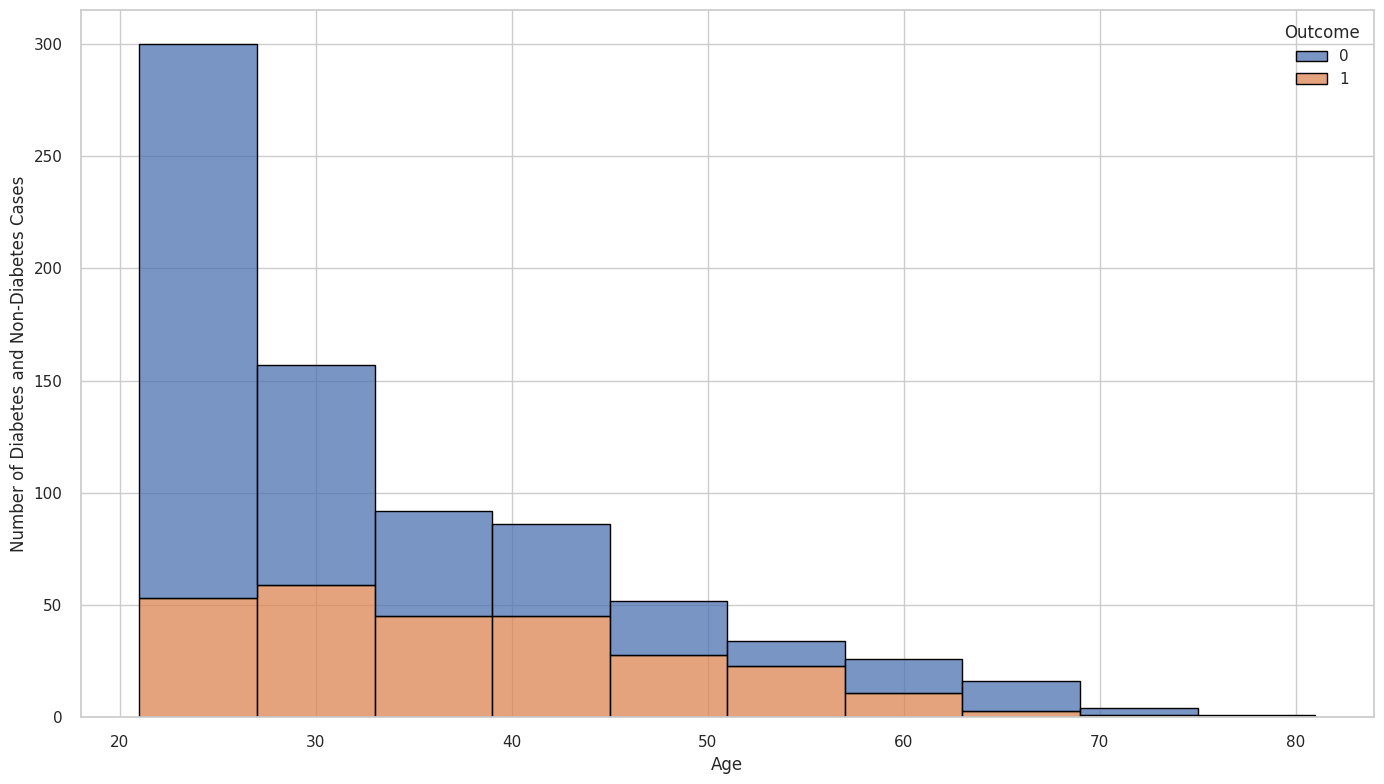

In [48]:
histogram('Age', 'Age')

In [49]:
def histogram(feature, xlabel):
    plt.figure(figsize=(14, 8))

    sns.histplot(data=df, x=feature, hue='Outcome',
                 bins=15, multiple='layer',
                 alpha=0.5, edgecolor='black')

    plt.xlabel(xlabel)
    plt.ylabel('Number of Diabetic and Non-Diabetic Cases')
    plt.legend(labels=['Diabetic', 'Non-Diabetic'])
    plt.tight_layout()
    plt.show()

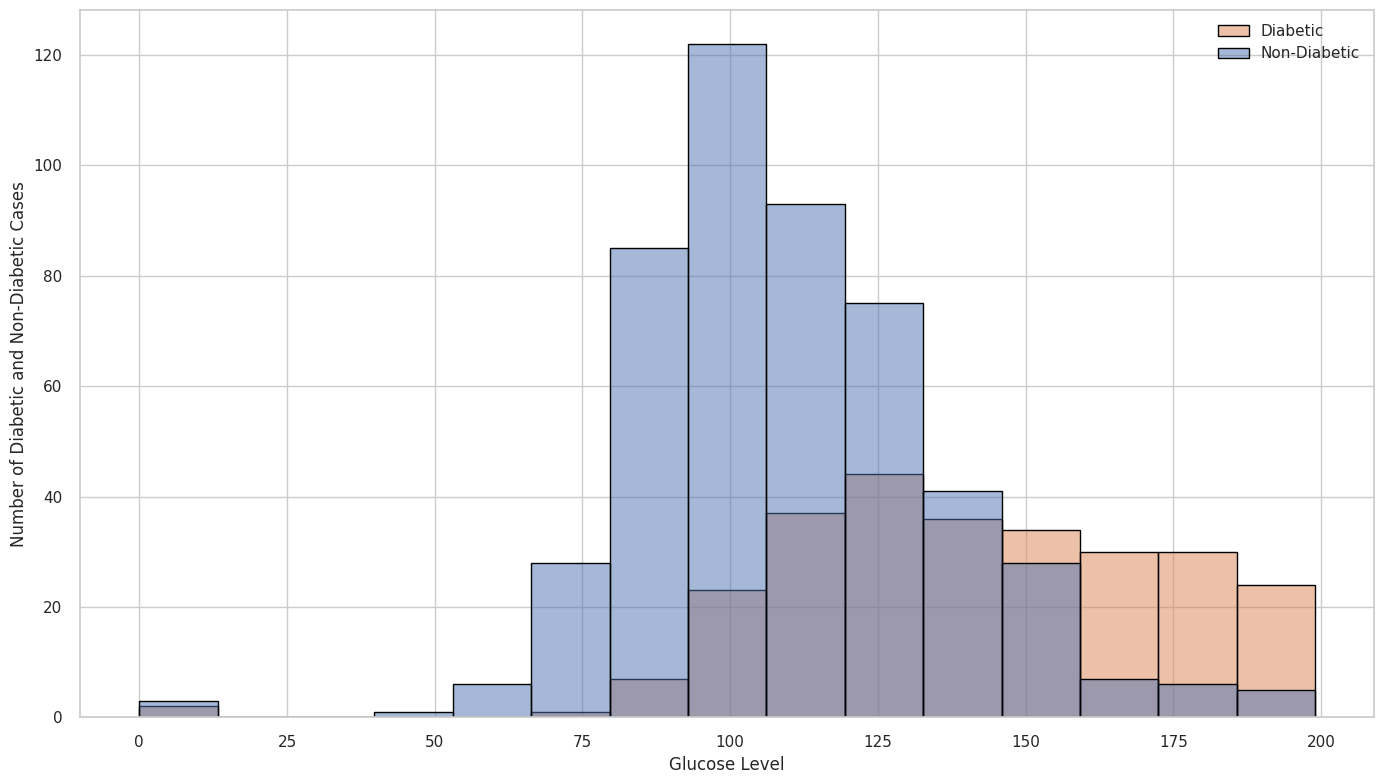

In [50]:
histogram('Glucose','Glucose Level')

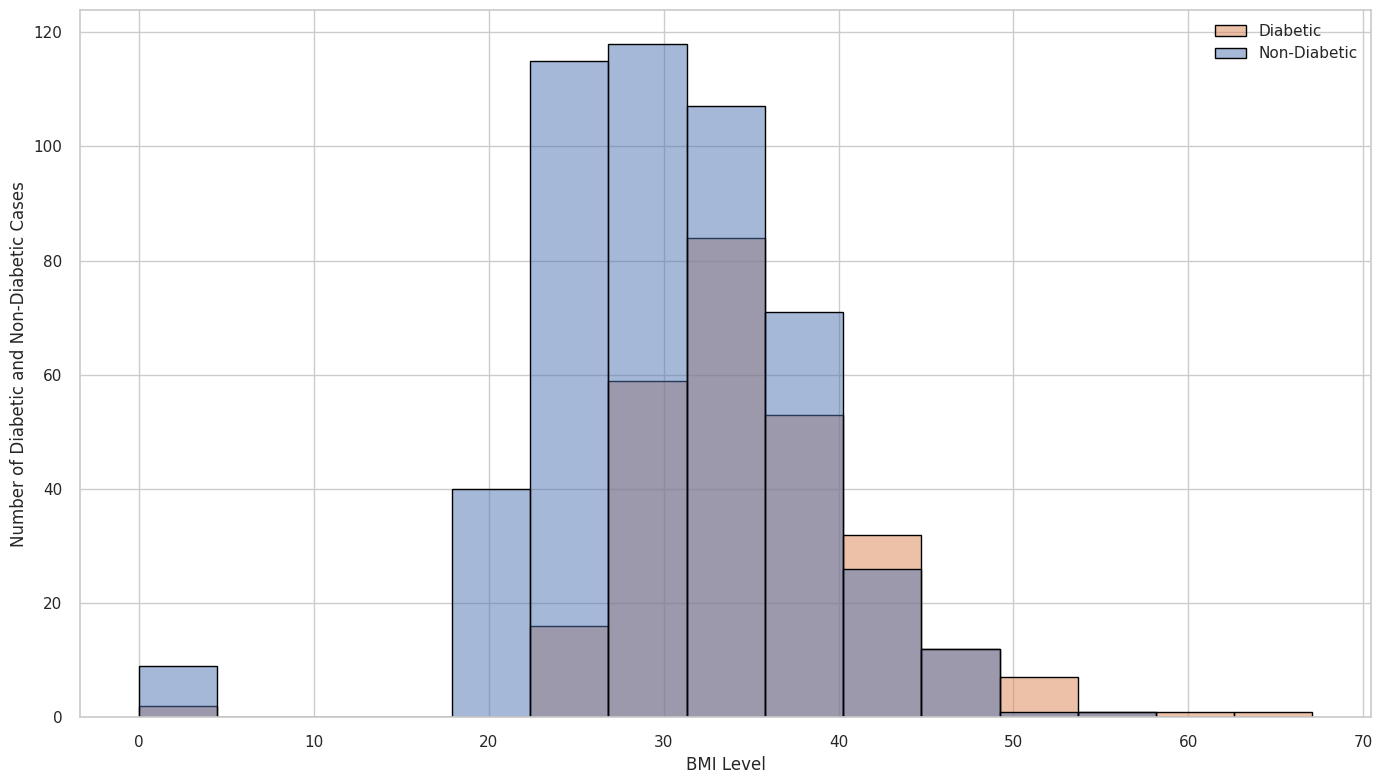

In [51]:
histogram('BMI','BMI Level')

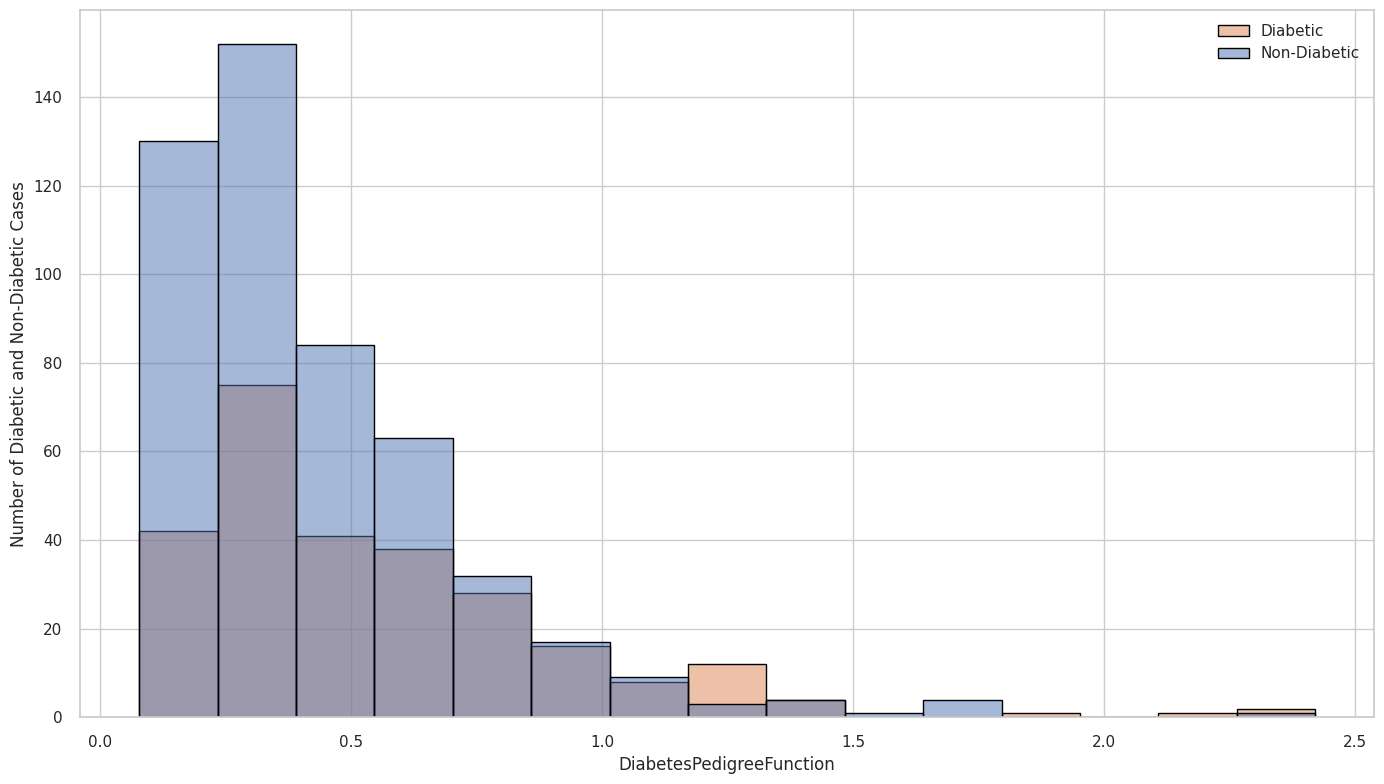

In [52]:
histogram('DiabetesPedigreeFunction','DiabetesPedigreeFunction')

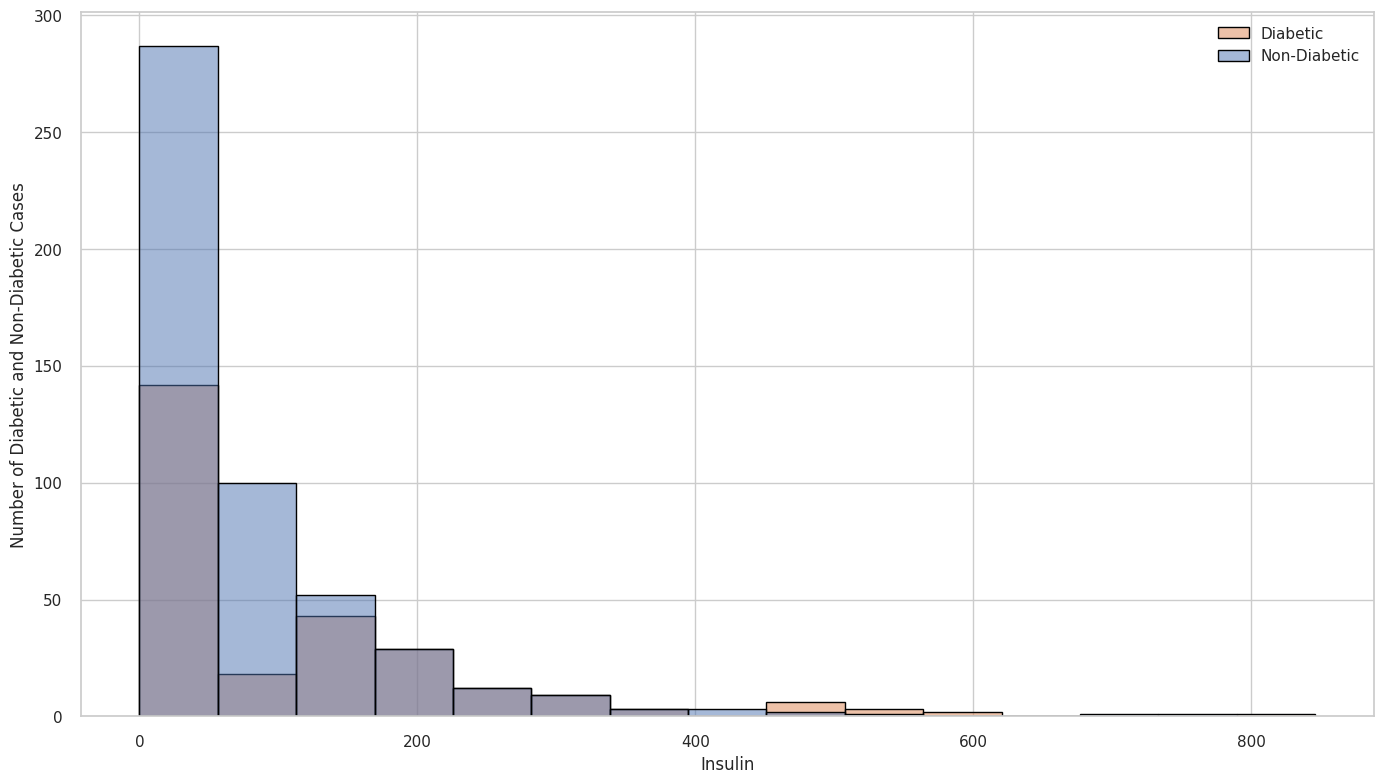

In [53]:
histogram('Insulin','Insulin')

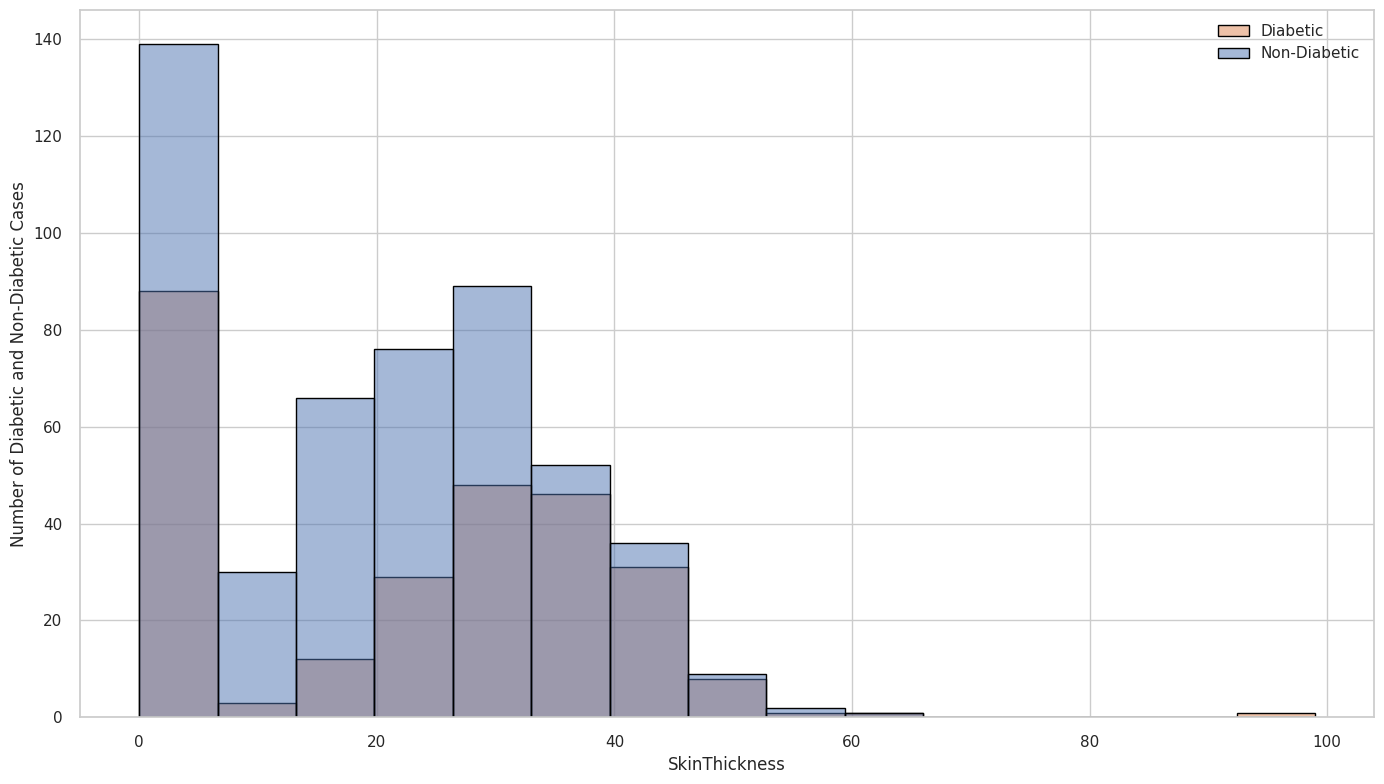

In [54]:
histogram('SkinThickness','SkinThickness')

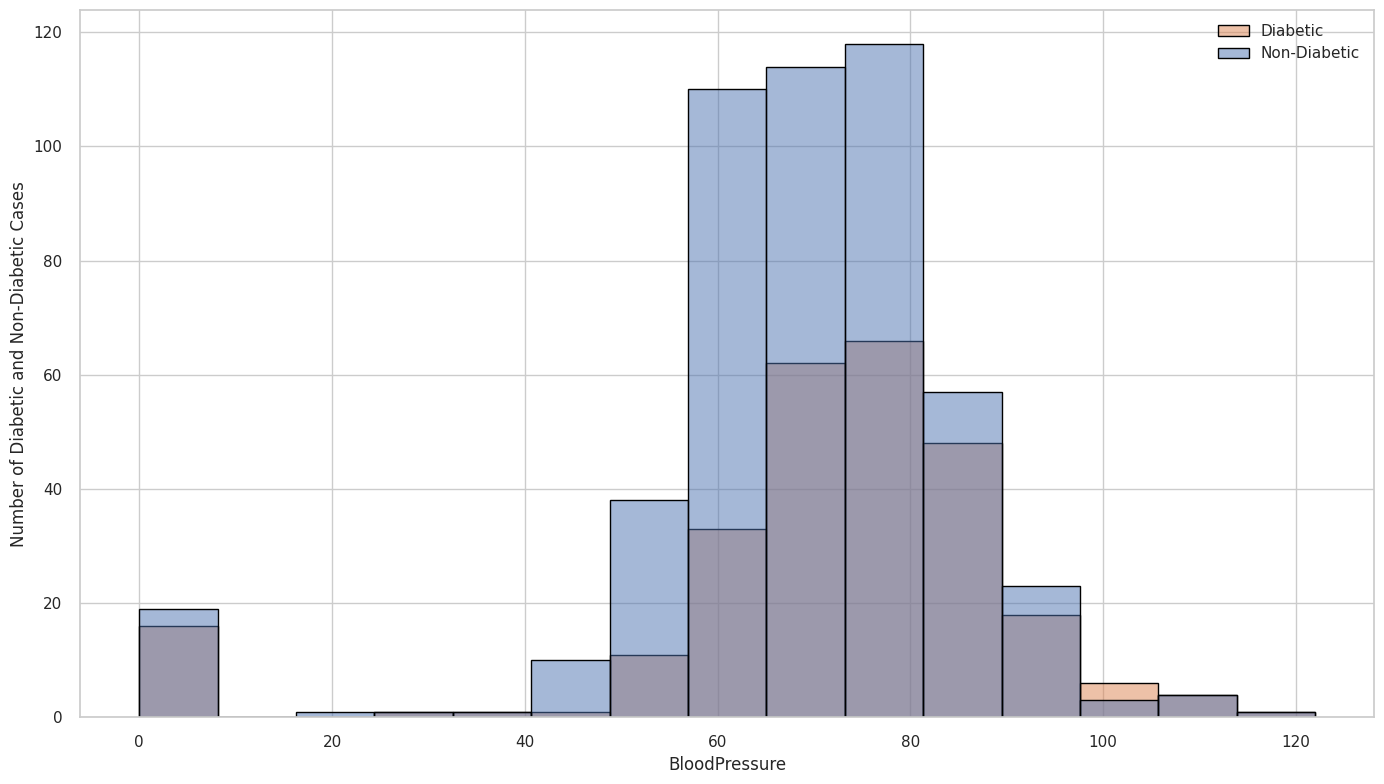

In [55]:
histogram('BloodPressure','BloodPressure')

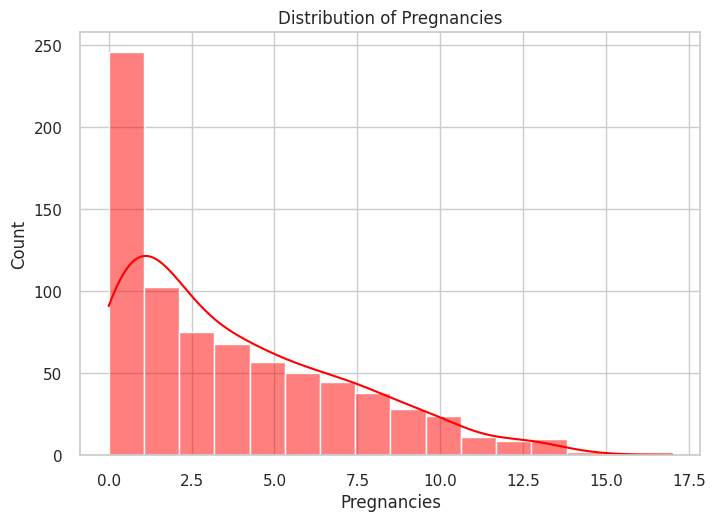

In [56]:
sns.histplot(df['Pregnancies'], kde=True, color='red')
plt.title('Distribution of Pregnancies')
plt.show()

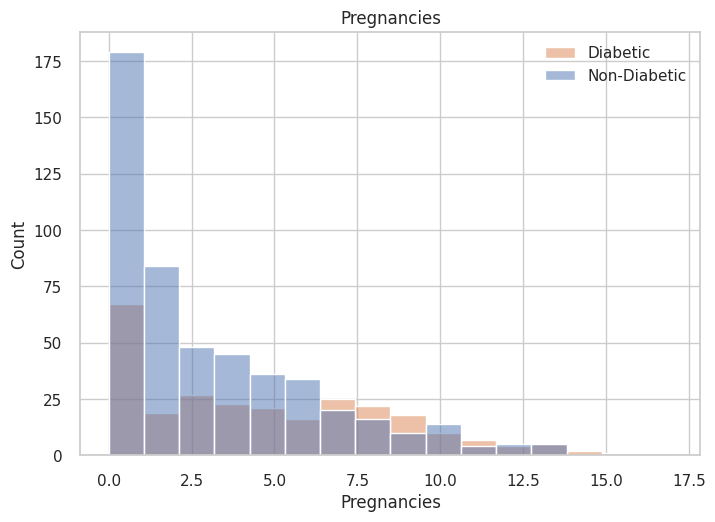

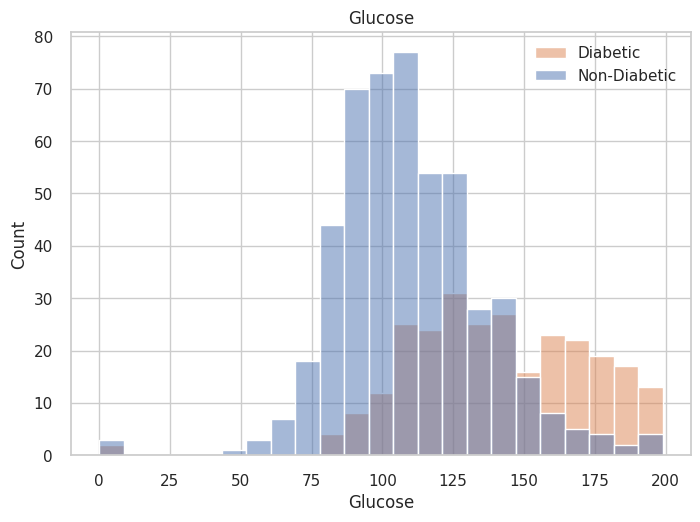

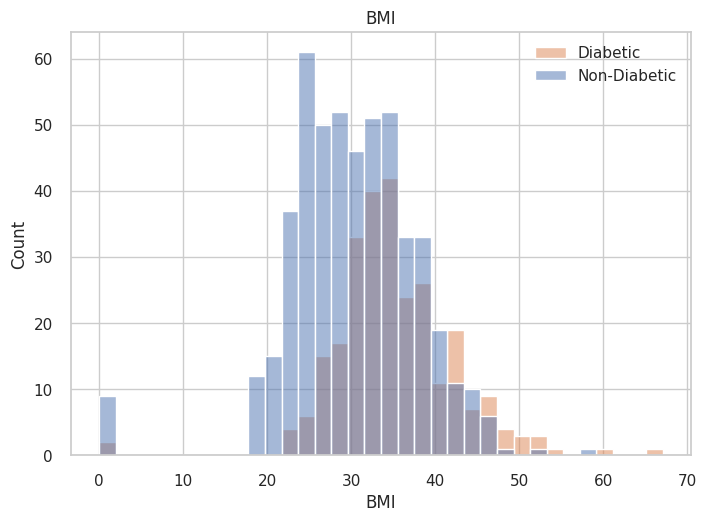

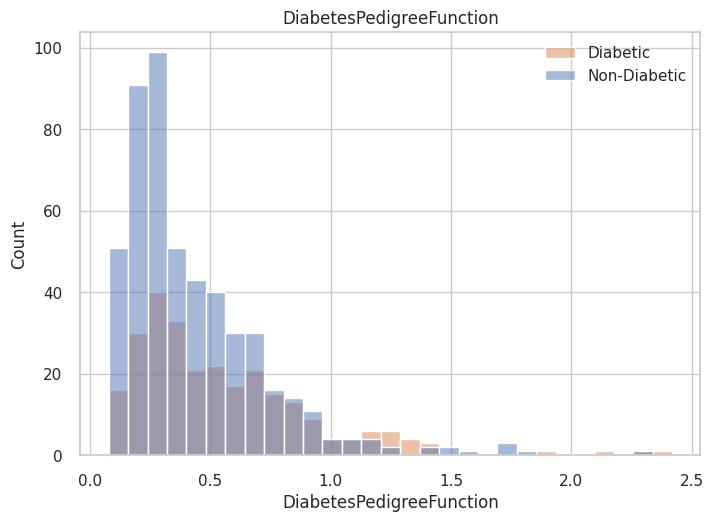

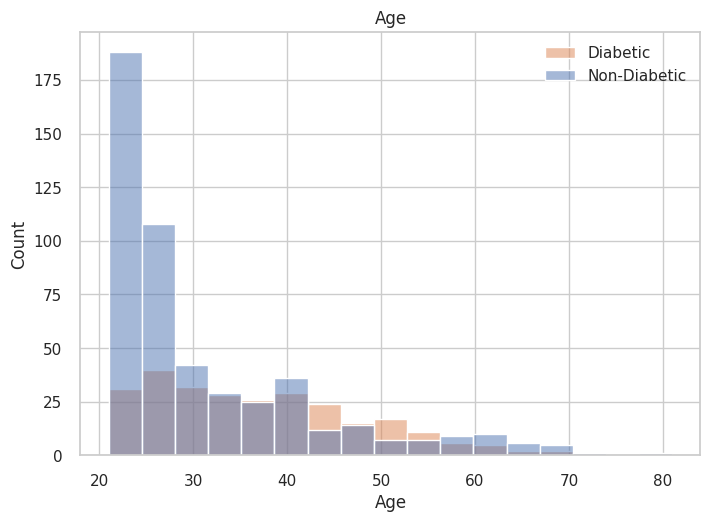

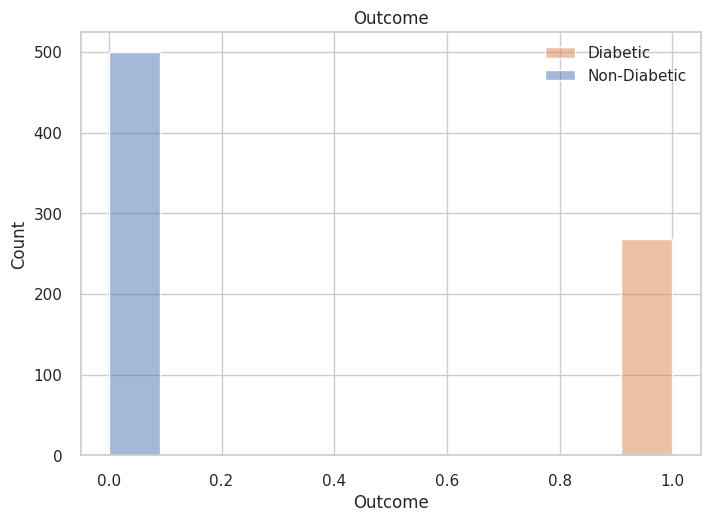

In [59]:
dftemp = df.drop(['Insulin', 'SkinThickness', 'BloodPressure'], axis=1)
for feature in dftemp:
    sns.histplot(data = dftemp,x=feature, hue = 'Outcome')
    plt.legend(labels=['Diabetic', 'Non-Diabetic'])
    plt.title(feature)
    plt.show()